# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

Of everyone the model predicts has the disease, the percentage who actually have it.

2. Explain what "recall" represents in this context.

Of everyone who actually has the disease, the percentage the model correctly identifies.

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

I think missing someone who actually has the disease is more serious because it could prevent or delay them from getting proper treatment.

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

I would prefer higher recall because it means fewer people with the disease get missed.

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

The rule should be less strict, using a lower probability cutoff to flag more people as potentially having the disease.

6. What is a downside to your choice in the previous part?

It will create more false positives

In [ ]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [ ]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


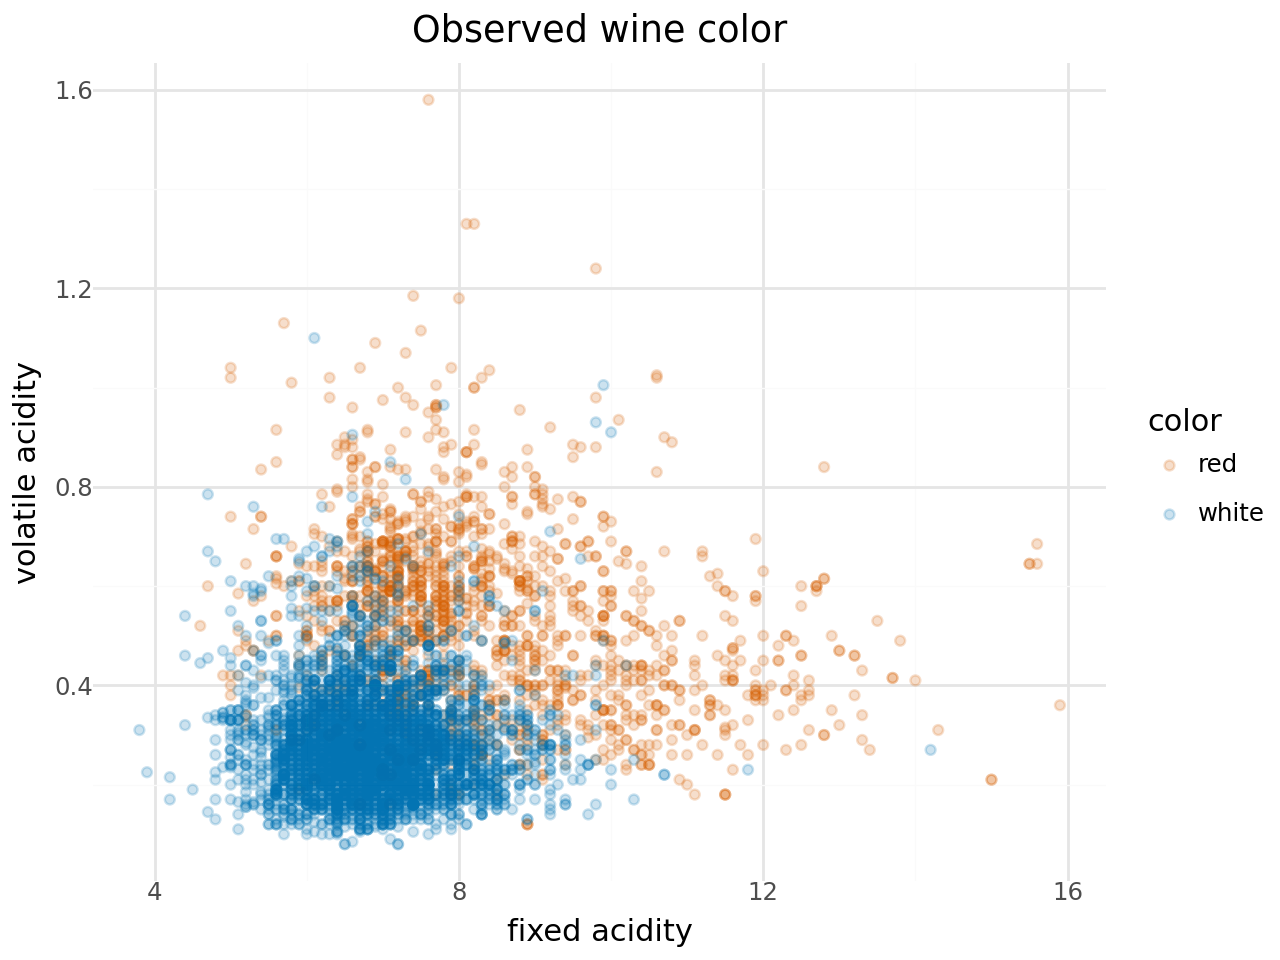

In [ ]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

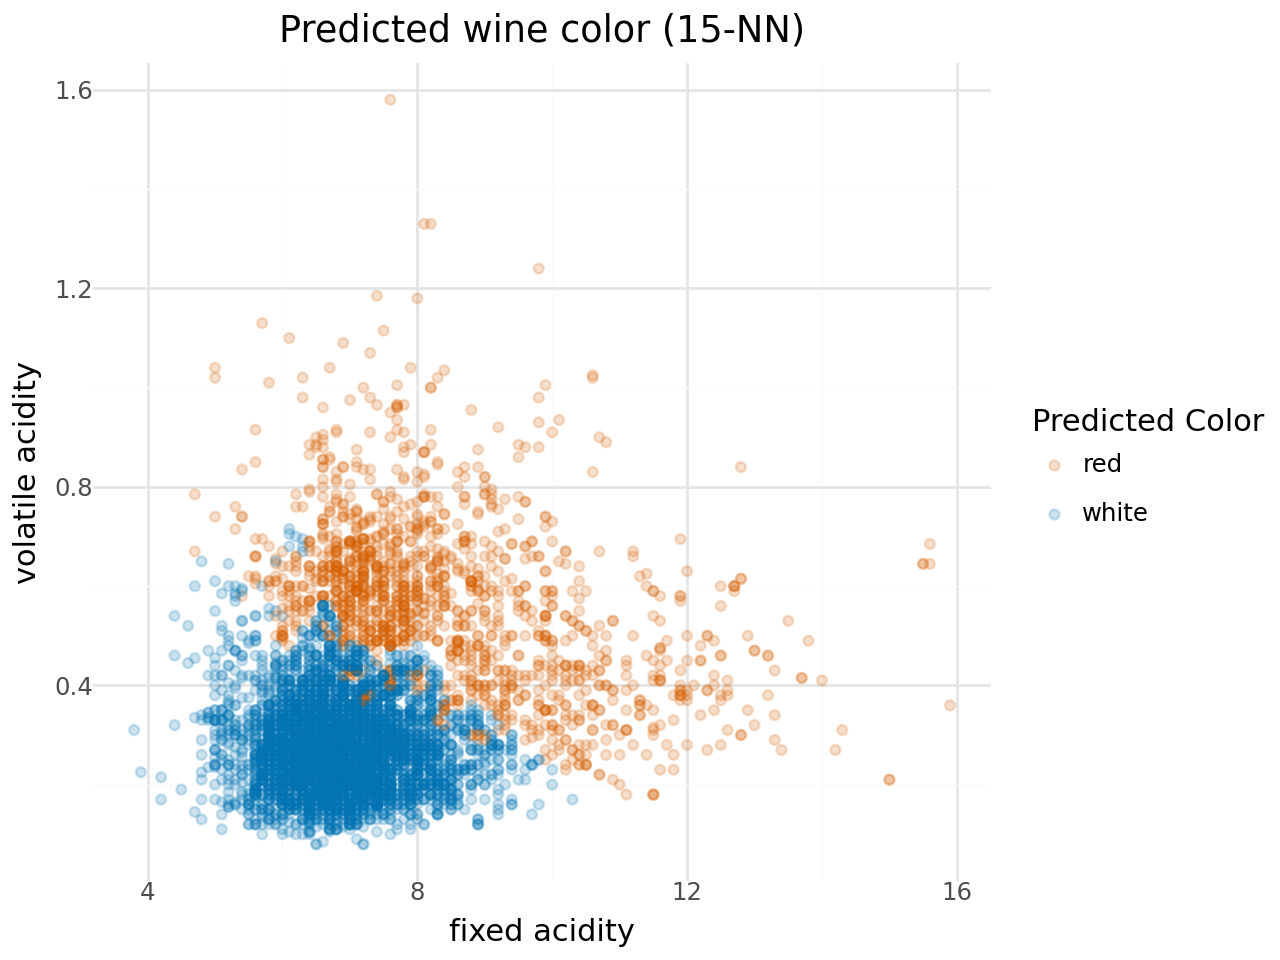

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from plotnine import *

X_train = df_train[["fixed acidity", "volatile acidity"]]
y_train = df_train["color"]

pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

pipeline.fit(X_train, y_train)

df_train["predicted_color"] = pipeline.predict(X_train)

plot = (
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="predicted_color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (15-NN)", color="Predicted Color")
    + theme_minimal()
)
plot

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [ ]:
from sklearn.model_selection import cross_validate

scoring = ["precision_macro", "recall_macro", "f1_macro"]

scores = cross_validate(pipeline, X_train, y_train, cv=10, scoring=scoring)

print("10-Fold CV Metrics (macro scoring):")
print(f"Precision: {scores['test_precision_macro'].mean():.4f}")
print(f"Recall:    {scores['test_recall_macro'].mean():.4f}")
print(f"F1 Score:  {scores['test_f1_macro'].mean():.4f}")

10-Fold CV Metrics (macro scoring):
Precision: 0.8817
Recall:    0.8543
F1 Score:  0.8634


3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

Best k: 16 (F1 Macro score: 0.8669)


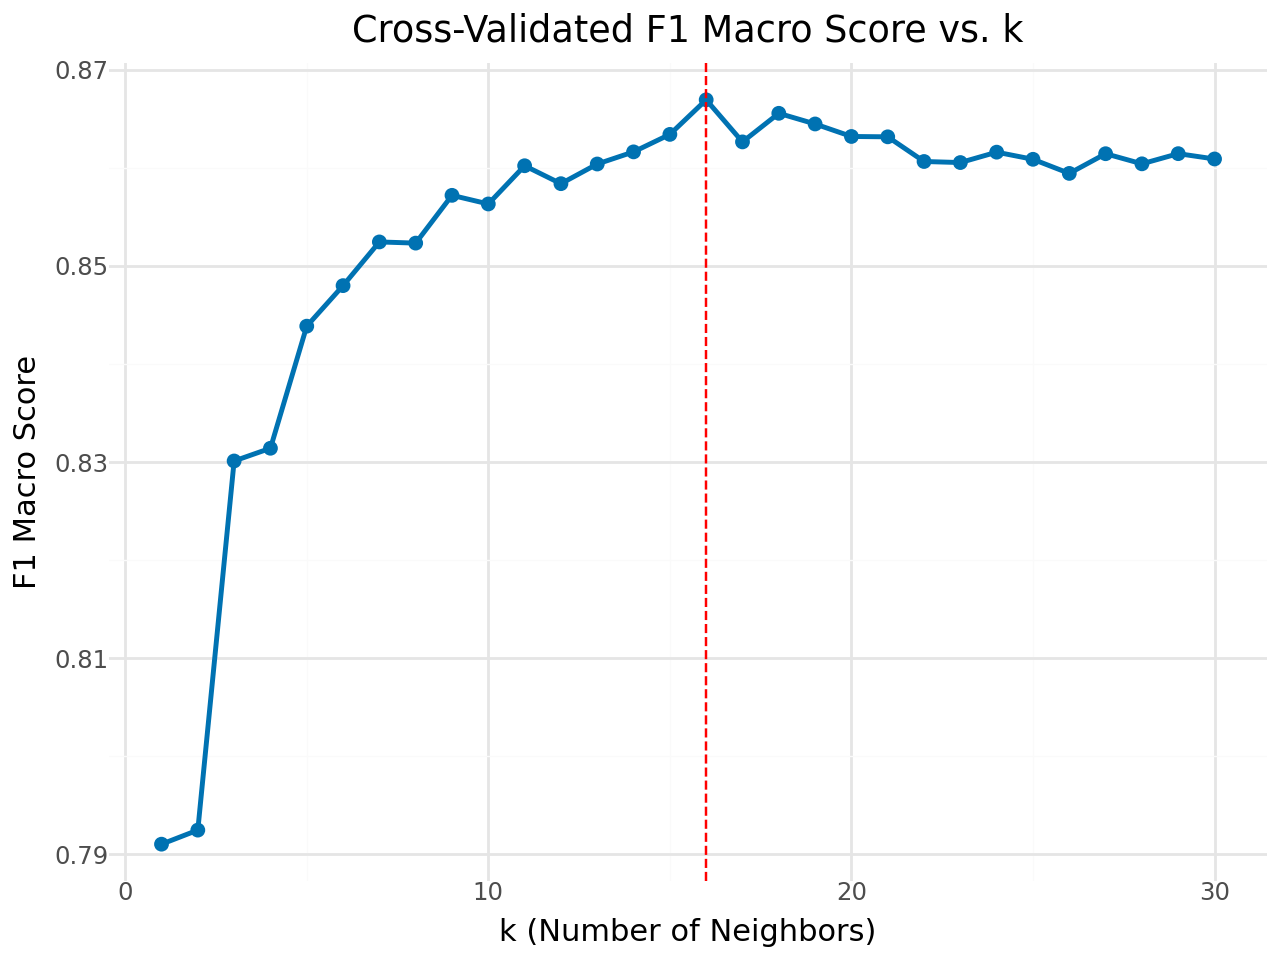

In [ ]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from plotnine import *

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors": range(1, 31)
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=10,
    scoring="f1_macro",
    return_train_score=False
)

grid_search.fit(X_train, y_train)

results_df = pd.DataFrame({
    "k": range(1, 31),
    "f1_macro": grid_search.cv_results_["mean_test_score"]
})

best_k = grid_search.best_params_["knn__n_neighbors"]
best_score = grid_search.best_score_
print(f"Best k: {best_k} (F1 Macro score: {best_score:.4f})")

plot = (
    ggplot(results_df, aes(x="k", y="f1_macro"))
    + geom_line(color="#0072B2", size=1)
    + geom_point(color="#0072B2", size=2)
    + geom_vline(xintercept=best_k, linetype="dashed", color="red")
    + labs(title="Cross-Validated F1 Macro Score vs. k", x="k (Number of Neighbors)", y="F1 Macro Score")
    + theme_minimal()
)
plot

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

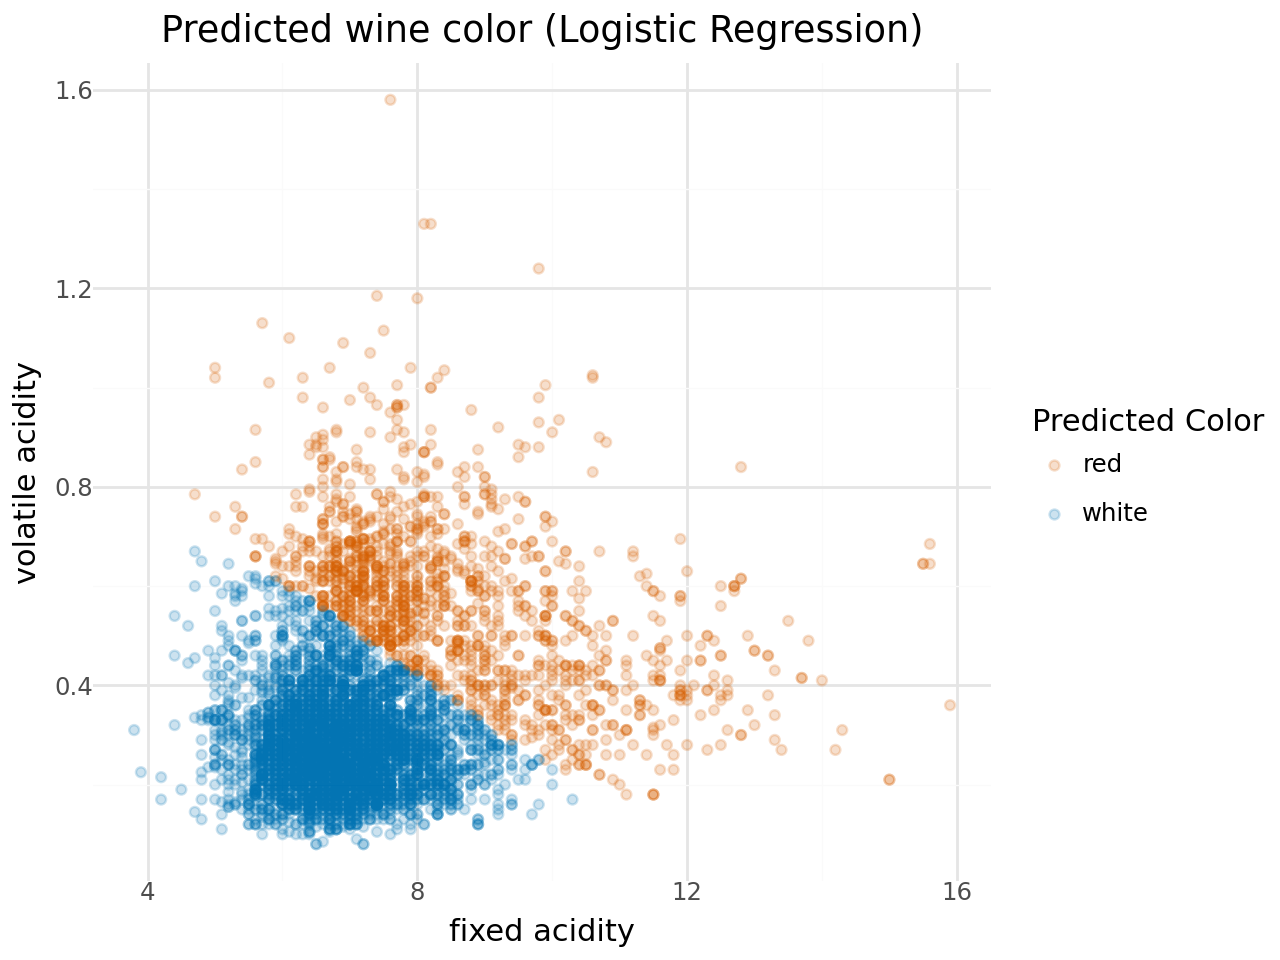

In [ ]:
from sklearn.linear_model import LogisticRegression
from plotnine import *

X_train = df_train[["fixed acidity", "volatile acidity"]]
y_train = df_train["color"]


log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

df_train["predicted_color_logreg"] = log_reg.predict(X_train)

plot = (
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="predicted_color_logreg"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (Logistic Regression)", color="Predicted Color")
    + theme_minimal()
)
plot

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression

log_reg_model = LogisticRegression()

scoring = ["precision_macro", "recall_macro", "f1_macro"]
scores_lr = cross_validate(log_reg_model, X_train, y_train, cv=10, scoring=scoring)


print("Logistic Regression (10-Fold CV, Macro):")
print(f"Precision: {scores_lr['test_precision_macro'].mean():.4f}")
print(f"Recall:    {scores_lr['test_recall_macro'].mean():.4f}")
print(f"F1 Score:  {scores_lr['test_f1_macro'].mean():.4f}")

print("\nComparison to 15-Nearest Neighbors:")
print("15-NN Precision: 0.8817 | Logistic Regression Precision: {:.4f}".format(scores_lr['test_precision_macro'].mean()))
print("15-NN Recall:    0.8543 | Logistic Regression Recall:    {:.4f}".format(scores_lr['test_recall_macro'].mean()))
print("15-NN F1 Score:  0.8634 | Logistic Regression F1 Score:  {:.4f}".format(scores_lr['test_f1_macro'].mean()))

Logistic Regression (10-Fold CV, Macro):
Precision: 0.8926
Recall:    0.8451
F1 Score:  0.8604

Comparison to 15-Nearest Neighbors:
15-NN Precision: 0.8817 | Logistic Regression Precision: 0.8926
15-NN Recall:    0.8543 | Logistic Regression Recall:    0.8451
15-NN F1 Score:  0.8634 | Logistic Regression F1 Score:  0.8604


6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression

X_all = df_train.drop(columns=["color", "predicted_color", "predicted_color_logreg"], errors="ignore")
y_all = df_train["color"]

log_reg_all = LogisticRegression(max_iter=1000)

scoring = ["precision_macro", "recall_macro", "f1_macro"]
scores_all = cross_validate(log_reg_all, X_all, y_all, cv=10, scoring=scoring)

print("Logistic Regression with All Predictors (10-Fold CV, Macro):")
print(f"Precision: {scores_all['test_precision_macro'].mean():.4f}")
print(f"Recall:    {scores_all['test_recall_macro'].mean():.4f}")
print(f"F1 Score:  {scores_all['test_f1_macro'].mean():.4f}")

Logistic Regression with All Predictors (10-Fold CV, Macro):
Precision: 0.9839
Recall:    0.9758
F1 Score:  0.9796


7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_all = df_train.drop(columns=["color", "predicted_color", "predicted_color_logreg"], errors="ignore")
y_all = df_train["color"]

lasso_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="l1", solver="liblinear", C=1.0)
)

scoring = ["precision_macro", "recall_macro", "f1_macro"]
scores_lasso = cross_validate(lasso_pipeline, X_all, y_all, cv=10, scoring=scoring)

print("LASSO Logistic Regression with All Predictors (10-Fold CV, Macro):")
print(f"Precision: {scores_lasso['test_precision_macro'].mean():.4f}")
print(f"Recall:    {scores_lasso['test_recall_macro'].mean():.4f}")
print(f"F1 Score:  {scores_lasso['test_f1_macro'].mean():.4f}")

LASSO Logistic Regression with All Predictors (10-Fold CV, Macro):
Precision: 0.9922
Recall:    0.9904
F1 Score:  0.9913
